In [5]:
print("Hello! Python is working.")

Hello! Python is working.


In [6]:
import pandas as pd
import numpy as np

np.random.seed(42)

sales = pd.DataFrame({
    "City": np.random.choice(
        ["Lagos", "Abuja", "Kano", "Ibadan", "Port Harcourt"], 1000
    ),
    "Product": np.random.choice(
        ["Rice", "Noodles", "Cooking Oil", "Beverages", "Detergent"], 1000
    ),
    "Quantity": np.random.randint(1, 21, 1000)
})

print("Dataset created successfully!")
print("Rows and columns:", sales.shape)
display(sales.head())

Dataset created successfully!
Rows and columns: (1000, 3)


,City,Product,Quantity
0,Ibadan,Beverages,7
1,Port Harcourt,Beverages,11
2,Kano,Beverages,10
3,Port Harcourt,Beverages,9
4,Port Harcourt,Detergent,14


In [11]:
import pandas as pd
import numpy as np

np.random.seed(42)

sales = pd.DataFrame({
    "City": np.random.choice(
        ["Lagos", "Abuja", "Kano", "Ibadan", "Port Harcourt"], 1000
    ),
    "Product": np.random.choice(
        ["Rice", "Noodles", "Cooking Oil", "Beverages", "Detergent"], 1000
    ),
    "Quantity": np.random.randint(1, 21, 1000)
})

prices = {
    "Rice": 75000, "Noodles": 1200, "Cooking Oil": 45000,
    "Beverages": 2500, "Detergent": 3500
}

costs = {
    "Rice": 60000, "Noodles": 850, "Cooking Oil": 35000,
    "Beverages": 1600, "Detergent": 2200
}

sales["Unit_Price_NGN"] = sales["Product"].map(prices)
sales["Unit_Cost_NGN"] = sales["Product"].map(costs)
sales["Revenue_NGN"] = sales["Quantity"] * sales["Unit_Price_NGN"]
sales["Profit_NGN"] = sales["Quantity"] * (
    sales["Unit_Price_NGN"] - sales["Unit_Cost_NGN"]
)

product_sales = sales.groupby("Product").agg(
    Units_Sold=("Quantity", "sum"),
    Revenue_NGN=("Revenue_NGN", "sum"),
    Profit_NGN=("Profit_NGN", "sum")
).sort_values("Revenue_NGN", ascending=False)

city_sales = sales.groupby("City").agg(
    Units_Sold=("Quantity", "sum"),
    Revenue_NGN=("Revenue_NGN", "sum"),
    Profit_NGN=("Profit_NGN", "sum")
).sort_values("Profit_NGN", ascending=False)

print("PRODUCT PERFORMANCE")
display(product_sales)

print("CITY PERFORMANCE")
display(city_sales)

print("Top product by revenue:", product_sales.index[0])
print("Most profitable city:", city_sales.index[0])

PRODUCT PERFORMANCE


,Units_Sold,Revenue_NGN,Profit_NGN
Product,,,
Rice,2077,155775000,31155000
Cooking Oil,2069,93105000,20690000
Detergent,2072,7252000,2693600
Beverages,1987,4967500,1788300
Noodles,2200,2640000,770000


CITY PERFORMANCE


,Units_Sold,Revenue_NGN,Profit_NGN
City,,,
Ibadan,2107,59682200,12839850
Port Harcourt,2204,55400400,11977300
Abuja,1932,54669100,11715050
Lagos,2265,50626800,11041500
Kano,1897,43361000,9523200


Top product by revenue: Rice
Most profitable city: Ibadan


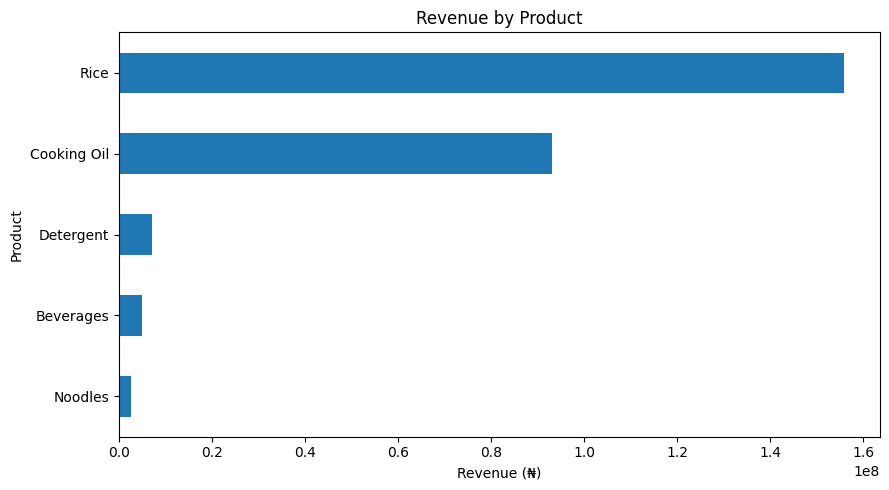

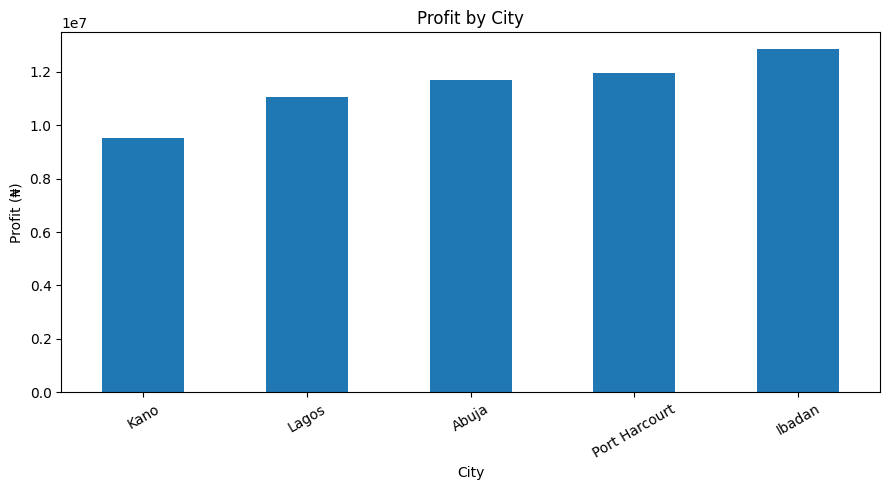

In [12]:
import matplotlib.pyplot as plt

# Chart 1: Revenue by product
product_sales["Revenue_NGN"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)

plt.title("Revenue by Product")
plt.xlabel("Revenue (₦)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# Chart 2: Profit by city
city_sales["Profit_NGN"].sort_values().plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Profit by City")
plt.xlabel("City")
plt.ylabel("Profit (₦)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [13]:
# Calculate profit margin for each sale
sales["Profit_Margin_%"] = (
    sales["Profit_NGN"] / sales["Revenue_NGN"] * 100
)

# Summarize profitability by product
profit_analysis = sales.groupby("Product").agg(
    Total_Revenue=("Revenue_NGN", "sum"),
    Total_Profit=("Profit_NGN", "sum"),
    Average_Profit_Margin=("Profit_Margin_%", "mean"),
    Total_Units_Sold=("Quantity", "sum")
).round(2)

profit_analysis = profit_analysis.sort_values(
    "Total_Profit", ascending=False
)

print("PRODUCT PROFITABILITY ANALYSIS")
display(profit_analysis)

print("\nBUSINESS INSIGHTS")
print("Most profitable product:",
      profit_analysis["Total_Profit"].idxmax())

print("Highest average margin product:",
      profit_analysis["Average_Profit_Margin"].idxmax())

print("Lowest average margin product:",
      profit_analysis["Average_Profit_Margin"].idxmin())

PRODUCT PROFITABILITY ANALYSIS


,Total_Revenue,Total_Profit,Average_Profit_Margin,Total_Units_Sold
Product,,,,
Rice,155775000,31155000,20.00,2077
Cooking Oil,93105000,20690000,22.22,2069
Detergent,7252000,2693600,37.14,2072
Beverages,4967500,1788300,36.00,1987
Noodles,2640000,770000,29.17,2200



BUSINESS INSIGHTS
Most profitable product: Rice
Highest average margin product: Detergent
Lowest average margin product: Rice


In [15]:
# Overall business performance
total_revenue = sales["Revenue_NGN"].sum()
total_profit = sales["Profit_NGN"].sum()
total_units = sales["Quantity"].sum()
overall_margin = total_profit / total_revenue * 100

best_product = profit_analysis["Total_Profit"].idxmax()
best_city = city_sales["Profit_NGN"].idxmax()

print("=" * 45)
print("NIGERIAN RETAIL SALES ANALYSIS")
print("=" * 45)

print(f"Total revenue: ₦{total_revenue:,.0f}")
print(f"Total profit: ₦{total_profit:,.0f}")
print(f"Total units sold: {total_units:,}")
print(f"Overall profit margin: {overall_margin:.2f}%")
print(f"Most profitable product: {best_product}")
print(f"Most profitable city: {best_city}")

print("\nBUSINESS RECOMMENDATIONS")
print("1. Monitor profit margins, not revenue alone.")
print("2. Review product-level costs and pricing.")
print("3. Compare city performance before allocating sales resources.")
print("4. Track sales over time before making expansion decisions.")

NIGERIAN RETAIL SALES ANALYSIS
Total revenue: ₦263,739,500
Total profit: ₦57,096,900
Total units sold: 10,405
Overall profit margin: 21.65%
Most profitable product: Rice
Most profitable city: Ibadan

BUSINESS RECOMMENDATIONS
1. Monitor profit margins, not revenue alone.
2. Review product-level costs and pricing.
3. Compare city performance before allocating sales resources.
4. Track sales over time before making expansion decisions.


## Objective
Analyze simulated retail transactions to understand product performance, revenue, profitability, and city-level sales patterns.

## Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

## Analysis
- Generated and explored a 1,000-record retail dataset.
- Calculated revenue, costs, profit, and profit margins.
- Compared sales and profitability across products and cities.
- Created charts to communicate business performance.
- Developed recommendations for pricing and sales resource allocation.

## Key Limitation
The dataset is synthetic and does not represent actual transactions or verified sales performance in Nigerian cities. The results demonstrate analytical methods rather than real market conditions.

## Business Value
This analysis demonstrates how businesses can use sales data to monitor profitability, compare product performance, and support commercial decisions.

## Future Improvements
Use verified Nigerian retail data, incorporate monthly sales trends, and investigate how inflation and changing costs affect product demand and profit margins.